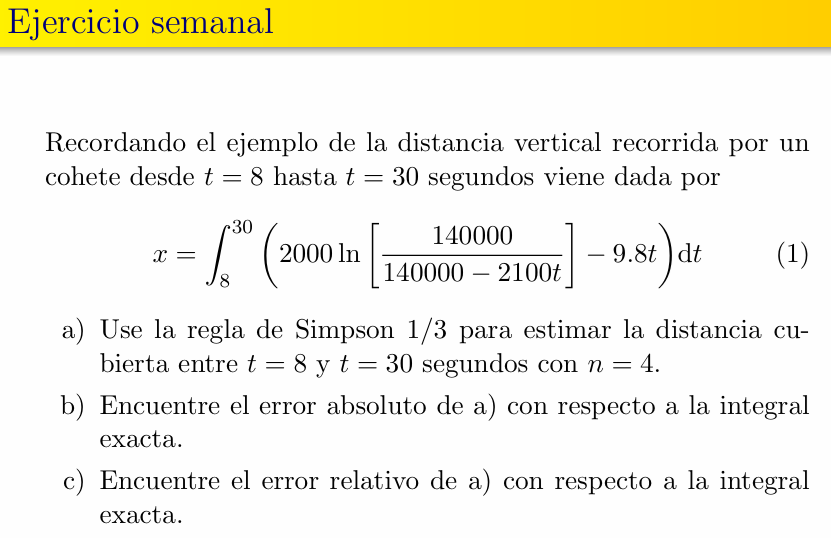

In [2]:
import math

# Constantes físicas
u = 2000.0
m0 = 140000.0
q = 2100.0
g = 9.8

def f(t):
    return u * math.log(m0 / (m0 - q * t)) - g * t

def integral_exacta(t):
    w = m0 - q * t
    return u * t * math.log(m0) + (u / q) * w * math.log(w) - (u / q) * w - 0.5 * g * (t**2)

# ==========================================
# a) Regla de Simpson 1/3 (n = 4)
# ==========================================
a = 8.0
b = 30.0
n = 4
h = (b - a) / n

t_vals = [a + i * h for i in range(n + 1)]
f_vals = [f(t) for t in t_vals]

simpson_aprox = (h / 3.0) * (f_vals[0] + 4*f_vals[1] + 2*f_vals[2] + 4*f_vals[3] + f_vals[4])

# ==========================================
# b) Error Absoluto
# ==========================================
valor_exacto = integral_exacta(b) - integral_exacta(a)
error_absoluto = abs(valor_exacto - simpson_aprox)

# ==========================================
# c) Error Relativo
# ==========================================
error_relativo = (error_absoluto / valor_exacto) * 100

print("a) Distancia estimada (Simpson 1/3) : {:.4f} m".format(simpson_aprox))
print("b) Error Absoluto                   : {:.4f} m".format(error_absoluto))
print("c) Error Relativo                   : {:.6f} %".format(error_relativo))

a) Distancia estimada (Simpson 1/3) : 11061.6361 m
b) Error Absoluto                   : 0.3006 m
c) Error Relativo                   : 0.002718 %


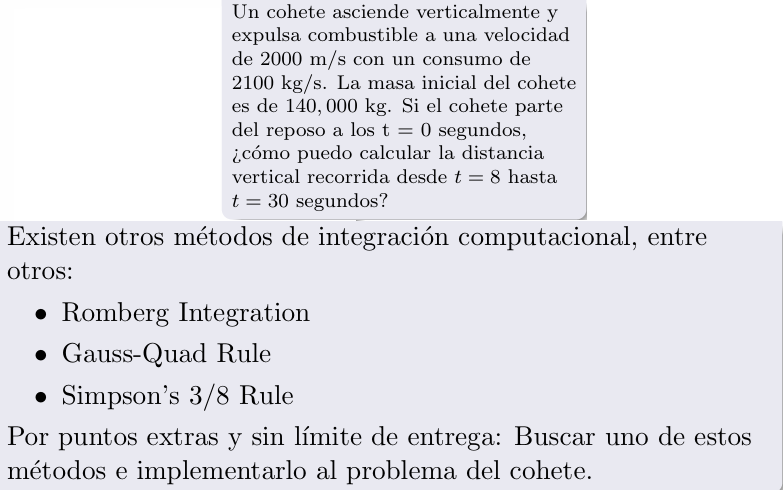


### Solución por Puntos Extra: Regla de Simpson 3/8 Compuesta

Para obtener los puntos extra, aplicaremos la **Regla de Simpson 3/8**, la cual es uno de los métodos de integración computacional sugeridos en el material. A diferencia de la regla de Simpson 1/3 (que ajusta una parábola usando 3 puntos), la regla de 3/8 ajusta un **polinomio cúbico** (de tercer grado) a través de 4 puntos igualmente espaciados para lograr una excelente precisión en curvas complejas.

Para aplicar la versión compuesta de este algoritmo numérico, el número de segmentos $n$ debe ser estrictamente un múltiplo de 3. La fórmula matemática para iterarlo es:
$$ I \approx \frac{3h}{8} \left[ f(x_0) + 3f(x_1) + 3f(x_2) + 2f(x_3) + 3f(x_4) + 3f(x_5) + 2f(x_6) + \dots + f(x_n) \right] $$

Donde el tamaño de paso es $h = \frac{b - a}{n}$. La teoría de Newton-Cotes dicta que los nodos que son múltiplos de 3 se ponderan con un factor de 2, los nodos extremos con 1, y todos los demás nodos internos se multiplican por 3.

Para resolver este problema del cohete que asciende desde $t=8$ hasta $t=30$, utilizaremos $n = 6$ sub-intervalos, lo que nos dará un tamaño de paso exacto de $h = \frac{30 - 8}{6} = 3.6667\text{ s}$.

In [3]:
import math

# Physical constants for the rocket problem
U = 2000.0
M0 = 140000.0
Q = 2100.0
G = 9.8

# Objective function for rocket velocity
def RocketVelocity(T):
    return U * math.log(M0 / (M0 - Q * T)) - G * T

# Analytical antiderivative for exact error calculation
def ExactIntegral(T):
    W = M0 - Q * T
    return U * T * math.log(M0) + (U / Q) * W * math.log(W) - (U / Q) * W - 0.5 * G * (T**2)

# Integration parameters (N must be a multiple of 3 for Simpson's 3/8)
A = 8.0
B = 30.0
N = 6
H = (B - A) / N

# Node generation and function evaluation
TVals = [A + I * H for I in range(N + 1)]
FVals = [RocketVelocity(T) for T in TVals]

# Composite Simpson's 3/8 Rule Algorithm
IntegralSum = FVals[0] + FVals[-1]

for I in range(1, N):
    if I % 3 == 0:
        # Nodes that are multiples of 3 are multiplied by 2
        IntegralSum += 2.0 * FVals[I]
    else:
        # All other internal nodes are multiplied by 3
        IntegralSum += 3.0 * FVals[I]

Simpson38Approx = (3.0 * H / 8.0) * IntegralSum

# Exact value and Errors Calculation
ExactValue = ExactIntegral(B) - ExactIntegral(A)
AbsoluteError = abs(ExactValue - Simpson38Approx)
RelativeError = (AbsoluteError / ExactValue) * 100.0

# Formatted Spanish outputs
print("--- Método de Simpson 3/8 Compuesto (n=6) ---")
print("Distancia estimada (Simpson 3/8) : {:.4f} m".format(Simpson38Approx))
print("Distancia analítica exacta       : {:.4f} m".format(ExactValue))
print("Error Absoluto                   : {:.4f} m".format(AbsoluteError))
print("Error Relativo                   : {:.6f} %".format(RelativeError))

--- Método de Simpson 3/8 Compuesto (n=6) ---
Distancia estimada (Simpson 3/8) : 11061.4697 m
Distancia analítica exacta       : 11061.3355 m
Error Absoluto                   : 0.1341 m
Error Relativo                   : 0.001213 %
